# Benchmarking the optimisers

This notebook compares every optimiser in `hybrid_ngd` against first-order baselines on three small tasks.

| optimiser | what it is |
|---|---|
| **SGD**, **Adam** | first-order baselines (`torch.optim`) |
| **NGD (direct)** | `torch_ngd.NGD`, with the dense metric solved by `torch.linalg.solve` |
| **NGD (JAX)** | `jax_ngd.NGD` under `jax.jit`: the same algorithm in the other framework |
| **K-FAC** | `torch_kfac.KFAC`, with Kronecker-factored blocks per layer |
| **NGD (HHL)** | NGD solved by `QiskitHHLSolver(6, match_damping_to_clock=True)` |
| **NGD (HHL, plain)** | NGD solved by `QiskitHHLSolver(6)`, without clock-matched damping |
| **K-FAC (auto, HHL)** | `KFAC(structure="auto")`, factorised to fit an HHL qubit budget (section 5) |
| **M-FAC** | `torch_mfac.MFAC`, with the empirical Fisher of the last 32 gradients, applied matrix-free |
| **M-FAC (window 8)** | the same with an 8-gradient window: the classical twin of M-FAC (HHL) |
| **M-FAC (HHL)** | M-FAC with its $8\times8$ system solved by `QiskitHHLSolver(10, match_damping_to_clock=True)`: 3 + 10 + 1 = 14 qubits (section 6) |
| **M-FAC (JAX)** | `jax_mfac.MFAC` under `jax.jit`: the same algorithm as M-FAC |
| **M-FAC (micro-batch)** | `MFAC(gradients="microbatch", window=32)`: curvature from 32 micro-batch gradients of the *current* step (section 7) |

**Protocol.**
* Each optimiser's learning rate is tuned per task on a small grid, using seed 0 and the final evaluation loss.
  For M-FAC, the learning rate and damping are tuned jointly, because they interact strongly on these small
  models. The HHL variants reuse their classical twin's settings.
* The tuned settings are then run with 3 initialisation seeds. Plots show the median and the min–max band.
  Tuning on a single seed favours lucky runs for optimisers that are sensitive to small perturbations. M-FAC on
  task A is the clear case (section 6).
* NGD and K-FAC use a fixed damping of $10^{-2}$. The M-FAC variants tune their damping too, which matters when
  comparing them with NGD (see the takeaways). Tables show M-FAC settings as "lr, λ".
* Timing covers only optimiser steps, not evaluation, measured on CPU in float64.

**Read the HHL timings with care.** They measure the cost of *simulating* the circuit on a classical computer,
which grows exponentially with qubit count. They say nothing about how long a quantum computer would take. What
transfers to hardware are the loss curves: how well training works with a quantum linear solver's errors.

The whole notebook takes about 10–12 minutes on a 12-core CPU, mostly dense torch NGD on task B and the simulated
HHL runs.

**Machine setup.** On this machine, OpenBLAS's default multithreading made small dense solves in NumPy and JAX
100–1,000× slower: a $322\times322$ solve took 723 ms with 12 threads and 0.9 ms with 1. Torch uses its own
BLAS and is unaffected. The first cell therefore limits OpenBLAS to one thread *before* NumPy is imported, so the
timings measure the optimisers rather than thread contention. If your own JAX or NumPy solves are mysteriously
slow, try the same setting.

In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")  # must run before NumPy, JAX or SciPy is imported

import time
import warnings
from dataclasses import dataclass
from typing import Callable

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

from hybrid_ngd import QiskitHHLSolver
from hybrid_ngd.jax_mfac import MFAC as JaxMFAC
from hybrid_ngd.jax_ngd import NGD as JaxNGD
from hybrid_ngd.torch_kfac import KFAC
from hybrid_ngd.torch_mfac import MFAC
from hybrid_ngd.torch_ngd import NGD

torch.set_default_dtype(torch.float64)
jax.config.update("jax_enable_x64", True)
warnings.filterwarnings("ignore", message="Condition number exceeds")  # plain HHL's cut-off, expected below

**Saved results.** Every expensive computation below goes through `cached(name, compute, **settings)`. Its result
is saved next to this notebook in `results/benchmark_optimisers/` as two files. `<name>.npz` holds the NumPy arrays,
such as loss curves, timings and per-solve errors. `<name>.json` holds the structure around them, the settings
that produced them and the text the section printed. Neither file uses pickle, and both are read with
`allow_pickle=False`.

On a rerun, each section loads its files instead of recomputing, as long as its settings and the `hybrid_ngd`
source are unchanged. Otherwise that section recomputes and overwrites its files, so changing a plot reruns
nothing, and changing a grid reruns only the sections that use it. Set `RECOMPUTE = True`, or delete the folder,
to force a fresh run.

In [2]:
import contextlib
import hashlib
import io
import json
import pathlib
import sys

import hybrid_ngd

RECOMPUTE = False
RESULTS_DIR = pathlib.Path("results") / "benchmark_optimisers"
# Any change to the library's source invalidates every saved result.
LIBRARY_HASH = hashlib.sha256(b"".join(
    f.read_bytes() for f in sorted(pathlib.Path(hybrid_ngd.__file__).parent.rglob("*.py")))).hexdigest()[:16]


def encode(obj, arrays):
    # JSON-able tree; arrays go into `arrays` (saved to .npz) and are referenced by name.
    if isinstance(obj, np.ndarray):
        if obj.dtype == object:
            raise TypeError("object arrays cannot be saved without pickle")
        arrays[f"a{len(arrays)}"] = obj
        return {"__array__": f"a{len(arrays) - 1}"}
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, tuple):
        return {"__tuple__": [encode(v, arrays) for v in obj]}
    if isinstance(obj, list):
        return [encode(v, arrays) for v in obj]
    if isinstance(obj, dict):  # keys may be ints, floats or tuples, so store items as pairs
        return {"__items__": [[encode(k, arrays), encode(v, arrays)] for k, v in obj.items()]}
    if obj is None or isinstance(obj, (bool, int, float, str)):
        return obj
    raise TypeError(f"cannot save a {type(obj).__name__}")


def decode(obj, arrays):
    if isinstance(obj, list):
        return [decode(v, arrays) for v in obj]
    if isinstance(obj, dict):
        if "__array__" in obj:
            return arrays[obj["__array__"]]
        if "__tuple__" in obj:
            return tuple(decode(v, arrays) for v in obj["__tuple__"])
        return {decode(k, arrays): decode(v, arrays) for k, v in obj["__items__"]}
    return obj


class _Tee(io.TextIOBase):
    def __init__(self, *streams):
        self.streams = streams

    def write(self, text):
        for stream in self.streams:
            stream.write(text)
        return len(text)

    def flush(self):
        for stream in self.streams:
            stream.flush()


def save_result(name, key, value, output=""):
    arrays = {}
    tree = encode(value, arrays)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(RESULTS_DIR / f"{name}.npz", **arrays)
    (RESULTS_DIR / f"{name}.json").write_text(json.dumps({"key": key, "output": output, "value": tree}, indent=1))


def cached(name, compute, **settings):
    # Return compute(), or its saved result when the settings and library are unchanged; printed output is replayed.
    meta_path, array_path = RESULTS_DIR / f"{name}.json", RESULTS_DIR / f"{name}.npz"
    key = json.loads(json.dumps(encode({"library": LIBRARY_HASH, **settings}, {})))
    if meta_path.exists() and array_path.exists() and not RECOMPUTE:
        saved = json.loads(meta_path.read_text())
        if saved["key"] == key:
            with np.load(array_path, allow_pickle=False) as npz:
                arrays = {k: npz[k] for k in npz.files}
            print(f"[loaded {meta_path} and {array_path.name}]")
            print(saved["output"], end="")
            return decode(saved["value"], arrays)
        print(f"[{meta_path} was saved with different settings; recomputing]")
    buffer = io.StringIO()
    with contextlib.redirect_stdout(_Tee(sys.stdout, buffer)):
        value = compute()
    save_result(name, key, value, buffer.getvalue())
    return value

In [3]:
# Plot styling, shared with the other example notebooks. Each optimiser keeps one colour throughout: the 8
# palette slots in fixed order. A variant (M-FAC (JAX), K-FAC (auto, HHL)) shares its family's hue, with a
# dashed line or markers as a second cue. Table-only runs need no colour.
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {
    "Adam": "#2a78d6", "NGD (direct)": "#eb6834", "NGD (HHL)": "#1baf7a", "K-FAC": "#eda100",
    "SGD": "#e87ba4", "M-FAC": "#008300", "NGD (JAX)": "#6250d6", "M-FAC (HHL)": "#e34948",
}
DASHED = {"NGD (JAX)", "M-FAC (JAX)"}
DOTTED = {"M-FAC (micro-batch)"}


def color_of(name):
    return COLORS.get(name) or COLORS[name.split(" (")[0]]


def linestyle_of(name):
    return (0, (5, 3)) if name in DASHED else (0, (1, 1.5)) if name in DOTTED else "-"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 130, "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Tasks

* **A. Small classifier.** Two moons, 200 points, MLP 2 → 3 → 2 with tanh (**17 parameters**), cross-entropy,
  full batch, 60 steps. Small enough for every optimiser, including dense HHL (5 system qubits).
* **B. Wide classifier.** Noisier, overlapping moons (1,000 points, noise 0.3) with MLP 2 → 64 → 2
  (**322 parameters**), 60 steps. The overlap gives cross-entropy a real minimum (about 0.17). On the clean
  200-point data, a model this wide separates the classes and the loss falls towards zero, so larger learning
  rates always "win". Dense NGD solves a $322\times322$ system each step, which is too large for HHL.
* **C. Diffusion denoiser.** The DDPM noise predictor from `ngd_diffusion_torch.ipynb`: MLP 3 → 8 → 2 with SiLU
  (**50 parameters**), trained with the Gauss-Newton metric on fresh minibatches of 256, for 200 steps.

Each task also has a target loss. "Steps / time to target" is the first time the evaluation loss reaches it.

In [4]:
@dataclass
class Task:
    name: str
    metric: str  # "fisher" (values are per-sample losses) or "gauss_newton" (values are residuals)
    steps: int
    target: float
    make_model: Callable[[int], nn.Module]
    values: Callable  # (model, batch) -> per-sample losses or residuals
    eval_loss: Callable  # model -> float
    batches: Callable  # seed -> iterator of batches
    data: tuple = None  # (X, y) for the classification tasks


def objective(task, values):
    return per_sample_losses(task, values).mean()


def per_sample_losses(task, values):
    return values if task.metric == "fisher" else 0.5 * values.pow(2)


# --- A and B: two moons ---
def two_moons(n, noise, seed):
    rng = np.random.default_rng(seed)
    t, labels = rng.uniform(0, np.pi, n), rng.integers(0, 2, n)
    x = np.where(labels[:, None] == 0, np.c_[np.cos(t), np.sin(t)], np.c_[1 - np.cos(t), 0.5 - np.sin(t)])
    x = (x + noise * rng.normal(size=x.shape) - [0.5, 0.25]) / [0.9, 0.5]
    return torch.tensor(x), torch.tensor(labels)


cross_entropy = nn.CrossEntropyLoss(reduction="none")


def classifier(hidden):
    def make(seed):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(2, hidden), nn.Tanh(), nn.Linear(hidden, 2))
    return make


def full_batch(seed):
    while True:
        yield None


def moons_task(name, hidden, n, noise, target):
    X, y = two_moons(n, noise, seed=0)

    def values(model, batch):
        return cross_entropy(model(X), y)

    def eval_loss(model):
        with torch.no_grad():
            return values(model, None).mean().item()

    return Task(name, "fisher", 60, target, classifier(hidden), values, eval_loss, full_batch, data=(X, y))


# --- C: DDPM denoiser (as in ngd_diffusion_torch.ipynb) ---
T = 50
BETAS = torch.linspace(1e-4, 0.25, T)
ALPHA_BAR = torch.cumprod(1 - BETAS, dim=0)
CENTERS = torch.tensor([[1.0, 1.0], [-1.0, 1.0], [-1.0, -1.0], [1.0, -1.0]])


class Denoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, 8), nn.SiLU(), nn.Linear(8, 2))

    def forward(self, x, t):
        return self.net(torch.cat([x, (t / T)[:, None]], dim=1))


def make_denoiser(seed):
    torch.manual_seed(seed)
    return Denoiser()


def denoising_batch(n, g):
    x0 = CENTERS[torch.randint(0, 4, (n,), generator=g)] + 0.15 * torch.randn(n, 2, generator=g)
    t = torch.randint(0, T, (n,), generator=g)
    eps = torch.randn(n, 2, generator=g)
    xt = ALPHA_BAR[t].sqrt()[:, None] * x0 + (1 - ALPHA_BAR[t]).sqrt()[:, None] * eps
    return xt, t, eps


def denoising_batches(seed):
    g = torch.Generator().manual_seed(1000 + seed)
    while True:
        yield denoising_batch(256, g)


DENOISING_EVAL = denoising_batch(2000, torch.Generator().manual_seed(7))


def denoising_values(model, batch):
    xt, t, eps = batch
    return (model(xt, t) - eps).reshape(-1)


def denoising_loss(model):
    with torch.no_grad():
        return 0.5 * denoising_values(model, DENOISING_EVAL).pow(2).reshape(-1, 2).sum(1).mean().item()


TASKS = {
    "A": moons_task("A. small classifier (17 params)", hidden=3, n=200, noise=0.12, target=0.05),
    "B": moons_task("B. wide classifier (322 params)", hidden=64, n=1000, noise=0.3, target=0.22),
    "C": Task("C. diffusion denoiser (50 params)", "gauss_newton", 200, 0.30, make_denoiser, denoising_values,
              denoising_loss, denoising_batches),
}
for task in TASKS.values():
    print(f"{task.name:<36} parameters: {sum(p.numel() for p in task.make_model(0).parameters())}")

A. small classifier (17 params)      parameters: 17
B. wide classifier (322 params)      parameters: 322
C. diffusion denoiser (50 params)    parameters: 50


## 2. Optimisers and the training loop

In [5]:
DAMPING = 1e-2
LR_GRIDS = {
    "SGD": [0.1, 0.3, 1.0, 3.0, 10.0, 30.0],
    "Adam": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0],
    "NGD (direct)": [0.1, 0.3, 0.5, 1.0, 2.0, 5.0],
    "K-FAC": [0.1, 0.3, 0.5, 1.0, 2.0, 5.0],
}
MFAC_GRID = [(lr, damping) for damping in (1e-5, 1e-4, 1e-3, 1e-2, 1e-1) for lr in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0)]
LR_GRIDS["M-FAC"] = LR_GRIDS["M-FAC (window 8)"] = LR_GRIDS["M-FAC (micro-batch)"] = MFAC_GRID


def make_optimizer(name, model, lr, metric):
    if name == "SGD":
        return torch.optim.SGD(model.parameters(), lr=lr)
    if name == "Adam":
        return torch.optim.Adam(model.parameters(), lr=lr)
    if name == "NGD (direct)":
        return NGD(model.parameters(), lr=lr, damping=DAMPING, metric=metric)
    if name == "NGD (HHL)":
        solver = QiskitHHLSolver(num_clock_qubits=6, match_damping_to_clock=True)
        return NGD(model.parameters(), lr=lr, damping=DAMPING, metric=metric, solver=solver)
    if name == "NGD (HHL, plain)":
        return NGD(model.parameters(), lr=lr, damping=DAMPING, metric=metric, solver=QiskitHHLSolver(num_clock_qubits=6))
    if name == "K-FAC":
        return KFAC(model, lr=lr, damping=DAMPING, metric=metric)
    if name == "M-FAC (micro-batch)":
        return MFAC(model.parameters(), lr=lr[0], damping=lr[1], window=32, gradients="microbatch")
    if name in ("M-FAC", "M-FAC (window 8)", "M-FAC (HHL)"):
        step, damping = lr  # M-FAC settings are (lr, damping)
        window = 32 if name == "M-FAC" else 8
        solver = "direct"
        if name == "M-FAC (HHL)":
            solver = QiskitHHLSolver(num_clock_qubits=10, max_qubits=14, match_damping_to_clock=True)
        return MFAC(model.parameters(), lr=step, damping=damping, window=window, solver=solver)
    raise ValueError(name)


def run(task, name, lr, seed, steps=None, optimizer=None):
    # Train once. Returns the evaluation loss after each step and the cumulative optimiser time.
    steps = steps or task.steps
    model = task.make_model(seed)
    opt = optimizer(model) if optimizer else make_optimizer(name, model, lr, task.metric)
    batches = task.batches(seed)
    loss, elapsed = [task.eval_loss(model)], [0.0]
    for _ in range(steps):
        batch = next(batches)
        start = time.perf_counter()
        if isinstance(opt, (NGD, KFAC)):
            opt.step(lambda: task.values(model, batch))
        elif getattr(opt, "gradients", None) == "microbatch":  # M-FAC on the current step: per-sample losses
            opt.step(lambda: per_sample_losses(task, task.values(model, batch)))
        else:
            opt.zero_grad()
            objective(task, task.values(model, batch)).backward()
            opt.step()
        elapsed.append(elapsed[-1] + time.perf_counter() - start)
        loss.append(task.eval_loss(model))
        if not np.isfinite(loss[-1]) or loss[-1] > 1e3:  # diverged
            loss += [np.nan] * (steps + 1 - len(loss))
            elapsed += [np.nan] * (steps + 1 - len(elapsed))
            break
    return {"loss": np.array(loss), "time": np.array(elapsed)}


def fmt(hp):
    return f"{hp[0]:g}, λ={hp[1]:g}" if isinstance(hp, tuple) else f"{hp:g}"


def at_edge(grid, hp):
    if not isinstance(hp, tuple):
        return hp in (grid[0], grid[-1])
    axes = list(zip(*grid))  # (learning rates, dampings)
    return any(v in (min(axis), max(axis)) and len(set(axis)) > 1 for v, axis in zip(hp, axes))


def tune(task, names, steps=None):
    best = {}
    for name in names:
        scores = {hp: run(task, name, hp, seed=0, steps=steps)["loss"][-1] for hp in LR_GRIDS[name]}
        best[name] = min(scores, key=lambda hp: scores[hp] if np.isfinite(scores[hp]) else np.inf)
        if isinstance(best[name], tuple):  # report the joint grid compactly: the best few settings
            ranked = sorted(scores, key=lambda hp: scores[hp] if np.isfinite(scores[hp]) else np.inf)[:4]
            grid = "best: " + ", ".join(f"({fmt(hp)}): {scores[hp]:.3g}" for hp in ranked)
        else:
            grid = "final loss by lr: " + ", ".join(f"{hp:g}: {sc:.3g}" for hp, sc in scores.items())
        edge = "  <- at the edge of the grid" if at_edge(LR_GRIDS[name], best[name]) else ""
        print(f"  {name:<17} {fmt(best[name]):<14} ({grid}){edge}")
    return best


SEEDS = (0, 1, 2)


def benchmark(task, lrs):
    return {name: [run(task, name, lr, seed) for seed in SEEDS] for name, lr in lrs.items()}

In [6]:
def first_reach(h, target):
    hits = np.flatnonzero(h["loss"] <= target)
    return (int(hits[0]), h["time"][hits[0]]) if len(hits) else (None, None)


def summarise(task, results, lrs):
    print(f"{task.name}: target loss {task.target}")
    print(f"{'optimiser':<20}{'settings':>15}{'final loss (median, min-max)':>31}{'steps to target':>17}"
          f"{'time to target':>16}{'ms / step':>11}")
    for name, runs in results.items():
        finals = np.array([h["loss"][-1] for h in runs])
        reach = [first_reach(h, task.target) for h in runs]
        steps = [s for s, _ in reach if s is not None]
        times = [t for _, t in reach if t is not None]
        ms = np.median([np.nanmean(np.diff(h["time"])) * 1e3 for h in runs])
        reached = f"{int(np.median(steps))} ({len(steps)}/{len(runs)})" if steps else f"- (0/{len(runs)})"
        when = f"{np.median(times):.2f} s" if times else "-"
        spread = f"{np.nanmedian(finals):.4f} ({np.nanmin(finals):.4f}-{np.nanmax(finals):.4f})"
        print(f"{name:<20}{fmt(lrs[name]):>15}{spread:>31}{reached:>17}{when:>16}{ms:>11.1f}")


def plot_task(task, results, names=None, ylim=None):
    names = names or list(results)
    fig, (ax_step, ax_time) = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
    for name in names:
        losses = np.array([h["loss"] for h in results[name]])
        times = np.nanmedian(np.array([h["time"] for h in results[name]]), axis=0)
        median = np.nanmedian(losses, axis=0)
        style = dict(color=color_of(name), linestyle=linestyle_of(name))
        steps = np.arange(losses.shape[1])
        ax_step.plot(steps, median, label=name, **style)
        ax_step.fill_between(steps, np.nanmin(losses, 0), np.nanmax(losses, 0), color=color_of(name), alpha=0.12,
                             linewidth=0)
        ax_time.plot(times, median, **style)
    for ax in (ax_step, ax_time):
        ax.axhline(task.target, color=MUTED, linewidth=1, linestyle=(0, (2, 3)))
        ax.set_yscale("log")
        if ylim:
            ax.set_ylim(*ylim)
    ax_step.annotate("target", (0, task.target), xytext=(2, 3), textcoords="offset points", fontsize=9, color=INK_2)
    ax_step.set(xlabel="step", ylabel="evaluation loss (log scale)", title="Loss per step")
    ax_time.set(xlabel="optimiser wall-clock time, s (log scale)", xscale="log", title="Loss per second of compute")
    handles, labels = ax_step.get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 4), fontsize=10)
    fig.suptitle(f"{task.name}: median of {len(SEEDS)} seeds, band = min-max", color=INK)
    fig.tight_layout(rect=(0, 0.11, 1, 0.94))
    plt.show()

## 3. Results by task

### A. Small classifier (17 parameters)

In [7]:
task = TASKS["A"]


def compute_task_A():
    print("tuning:")
    lrs = tune(task, LR_GRIDS)
    lrs["NGD (HHL)"] = lrs["NGD (HHL, plain)"] = lrs["NGD (direct)"]
    lrs["M-FAC (HHL)"] = lrs["M-FAC (window 8)"]
    return lrs, benchmark(task, lrs)


lrs_A, results_A = cached("task_A", compute_task_A, grids=LR_GRIDS, seeds=SEEDS, damping=DAMPING)

[loaded results/benchmark_optimisers/task_A.json and task_A.npz]
tuning:
  SGD               3              (final loss by lr: 0.1: 0.357, 0.3: 0.305, 1: 0.291, 3: 0.257, 10: 0.3, 30: 4.56)
  Adam              0.3            (final loss by lr: 0.003: 0.606, 0.01: 0.365, 0.03: 0.283, 0.1: 0.237, 0.3: 0.0772, 1: 0.289, 3: 0.343)
  NGD (direct)      0.5            (final loss by lr: 0.1: 0.0173, 0.3: 0.00531, 0.5: 0.00425, 1: 0.0152, 2: 0.0285, 5: 0.0199)
  K-FAC             0.5            (final loss by lr: 0.1: 0.3, 0.3: 0.139, 0.5: 0.042, 1: 0.118, 2: 0.294, 5: 0.512)
  M-FAC             0.3, λ=0.01    (best: (0.3, λ=0.01): 0.0117, (0.03, λ=0.001): 0.0198, (0.1, λ=0.01): 0.0366, (0.01, λ=1e-05): 0.0532)
  M-FAC (window 8)  0.3, λ=0.01    (best: (0.3, λ=0.01): 0.0677, (0.03, λ=0.001): 0.0838, (1, λ=0.1): 0.0972, (0.1, λ=0.01): 0.112)
  M-FAC (micro-batch) 0.3, λ=0.001   (best: (0.3, λ=0.001): 0.00227, (0.1, λ=0.0001): 0.00289, (1, λ=0.01): 0.00464, (0.3, λ=0.01): 0.0052)


**NGD (JAX)** and **M-FAC (JAX)** run the same algorithms as their torch versions, so their trajectories should
match to rounding error. Their timings exclude the one-off `jax.jit` compilation, which is reported separately.

In [8]:
def jax_classifier_params(torch_model):
    first, last = torch_model[0], torch_model[2]
    return {k: jnp.asarray(v.detach().numpy()) for k, v in
            {"W1": first.weight, "b1": first.bias, "W2": last.weight, "b2": last.bias}.items()}


def jax_per_sample_ce(params, X, y):
    logits = jnp.tanh(X @ params["W1"].T + params["b1"]) @ params["W2"].T + params["b2"]
    return jax.nn.logsumexp(logits, axis=1) - jnp.take_along_axis(logits, y[:, None], axis=1)[:, 0]


def make_jax_optimizer(name, hp):
    if name == "M-FAC (JAX)":
        return JaxMFAC(jax_per_sample_ce, lr=hp[0], damping=hp[1], window=32)
    return JaxNGD(jax_per_sample_ce, lr=hp, damping=DAMPING, metric="fisher")


def run_jax(task, lr, seed, name="NGD (JAX)"):
    params = jax_classifier_params(task.make_model(seed))
    X, y = (jnp.asarray(a.numpy()) for a in task.data)
    opt = make_jax_optimizer(name, lr)
    update = jax.jit(opt.update)
    state = opt.init(params)
    start = time.perf_counter()
    jax.block_until_ready(update(params, state, X, y))  # compile once, outside the timed loop
    compile_seconds = time.perf_counter() - start
    loss, elapsed = [float(jax_per_sample_ce(params, X, y).mean())], [0.0]
    for _ in range(task.steps):
        start = time.perf_counter()
        params, state, _ = jax.block_until_ready(update(params, state, X, y))
        elapsed.append(elapsed[-1] + time.perf_counter() - start)
        loss.append(float(jax_per_sample_ce(params, X, y).mean()))
    return {"loss": np.array(loss), "time": np.array(elapsed), "compile": compile_seconds}


JAX_TWINS = [("NGD (JAX)", "NGD (direct)"), ("M-FAC (JAX)", "M-FAC")]
jax_A = cached("task_A_jax", lambda: {jax_name: [run_jax(task, lrs_A[torch_name], seed, jax_name) for seed in SEEDS]
                                      for jax_name, torch_name in JAX_TWINS},
               settings={t: lrs_A[t] for _, t in JAX_TWINS}, seeds=SEEDS, damping=DAMPING)
for jax_name, torch_name in JAX_TWINS:
    lrs_A[jax_name] = lrs_A[torch_name]
    results_A[jax_name] = jax_A[jax_name]
    gap = max(np.nanmax(np.abs(j["loss"] - t["loss"])) for j, t in zip(results_A[jax_name], results_A[torch_name]))
    compile_s = np.median([h["compile"] for h in results_A[jax_name]])
    print(f"{jax_name}: largest |loss(JAX) - loss(torch)| over all steps and seeds {gap:.1e}, jit compile {compile_s:.2f} s")
print()
summarise(task, results_A, lrs_A)

[loaded results/benchmark_optimisers/task_A_jax.json and task_A_jax.npz]
NGD (JAX): largest |loss(JAX) - loss(torch)| over all steps and seeds 9.3e-15, jit compile 0.11 s
M-FAC (JAX): largest |loss(JAX) - loss(torch)| over all steps and seeds 2.4e-07, jit compile 0.13 s

A. small classifier (17 params): target loss 0.05
optimiser                  settings   final loss (median, min-max)  steps to target  time to target  ms / step
SGD                               3         0.2567 (0.0473-0.3016)         59 (1/3)          0.11 s        2.0
Adam                            0.3         0.0188 (0.0110-0.0772)         45 (2/3)          0.09 s        1.9
NGD (direct)                    0.5         0.0043 (0.0042-0.0043)         11 (3/3)          0.11 s        6.9
K-FAC                           0.5         0.0420 (0.0297-0.1235)         53 (2/3)          0.16 s        3.0
M-FAC                   0.3, λ=0.01         0.1747 (0.0117-0.2086)         26 (1/3)          0.05 s        1.9
M-FAC (windo

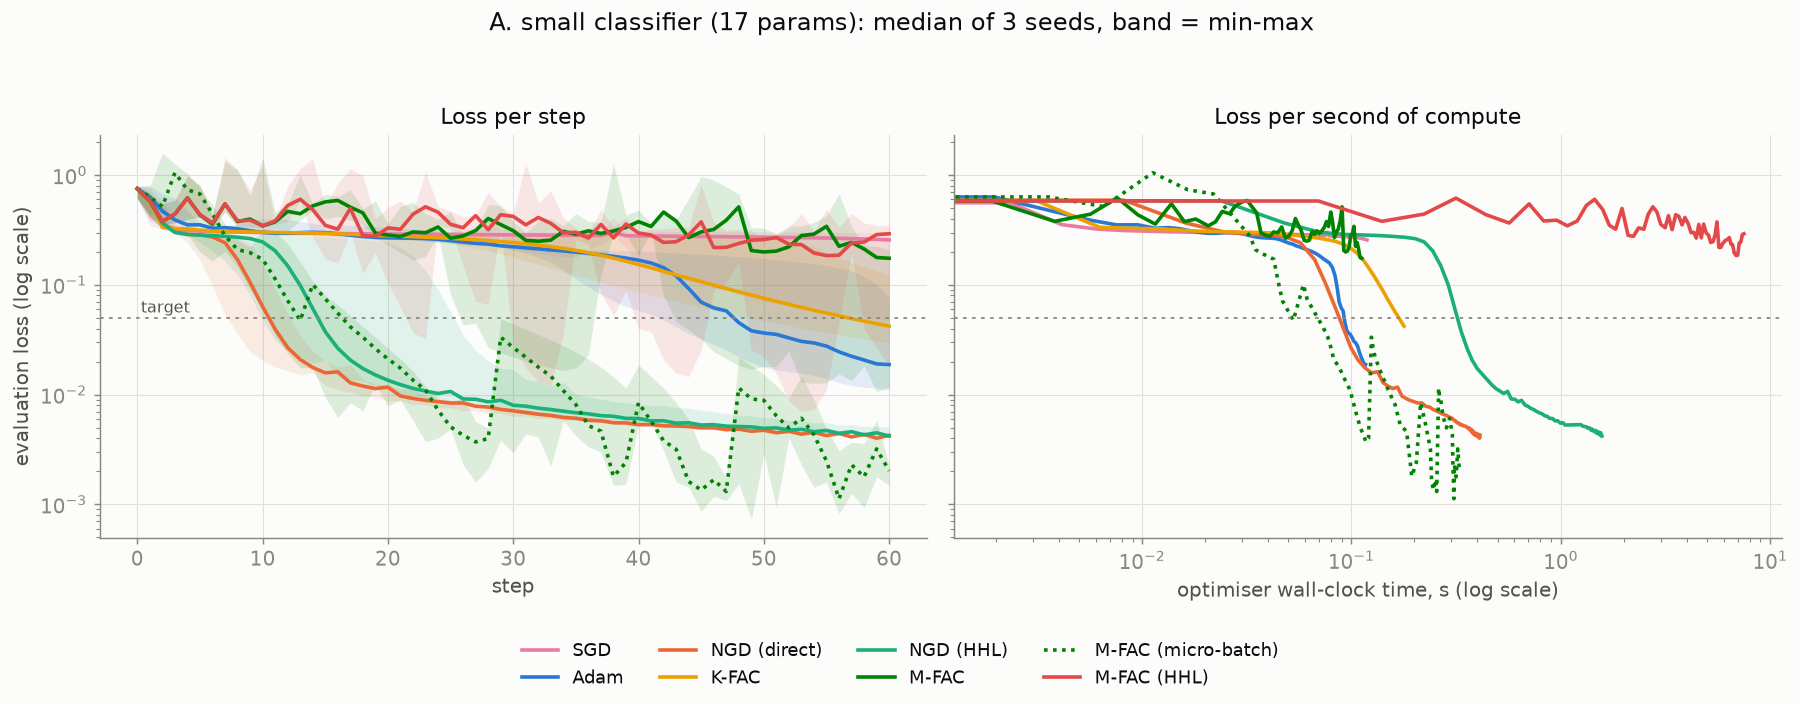

In [9]:
# NGD (JAX) matches NGD (direct) step for step (see above), so it is left out to keep 8 series; task B shows its timing.
plot_task(TASKS["A"], results_A, ["SGD", "Adam", "NGD (direct)", "K-FAC", "NGD (HHL)", "M-FAC", "M-FAC (micro-batch)",
                                  "M-FAC (HHL)"])

### B. Wide classifier (322 parameters)

Dense HHL would need 9 system qubits plus the clock, so NGD (HHL) does not run here. **M-FAC (HHL) does**: its
linear system is $8\times8$ whatever the model size, so it needs the same 14 qubits as on task A. Full NGD is tuned
with shorter runs (30 steps), because each of its torch steps is expensive.

[loaded results/benchmark_optimisers/task_B.json and task_B.npz]
tuning:
  SGD               1              (final loss by lr: 0.1: 0.3, 0.3: 0.297, 1: 0.272, 3: 0.633, 10: 3.39, 30: 9.79)
  Adam              0.1            (final loss by lr: 0.003: 0.297, 0.01: 0.264, 0.03: 0.183, 0.1: 0.179, 0.3: 0.18, 1: 1.12, 3: 2.62)
  K-FAC             1              (final loss by lr: 0.1: 0.2, 0.3: 0.181, 0.5: 0.178, 1: 0.171, 2: 0.232, 5: 1.35)
  M-FAC             0.003, λ=0.0001 (best: (0.003, λ=0.0001): 0.182, (0.01, λ=0.001): 0.183, (0.1, λ=0.01): 0.185, (0.001, λ=1e-05): 0.19)
  M-FAC (window 8)  0.01, λ=0.001  (best: (0.01, λ=0.001): 0.185, (0.1, λ=0.01): 0.187, (0.03, λ=0.001): 0.19, (0.03, λ=0.01): 0.201)
  M-FAC (micro-batch) 0.1, λ=0.001   (best: (0.1, λ=0.001): 0.168, (0.3, λ=0.001): 0.168, (0.3, λ=0.01): 0.174, (0.03, λ=0.0001): 0.174)
  NGD (direct)      2              (final loss by lr: 0.1: 0.186, 0.3: 0.178, 0.5: 0.176, 1: 0.173, 2: 0.172, 5: 0.282)

B. wide classifier (322 para

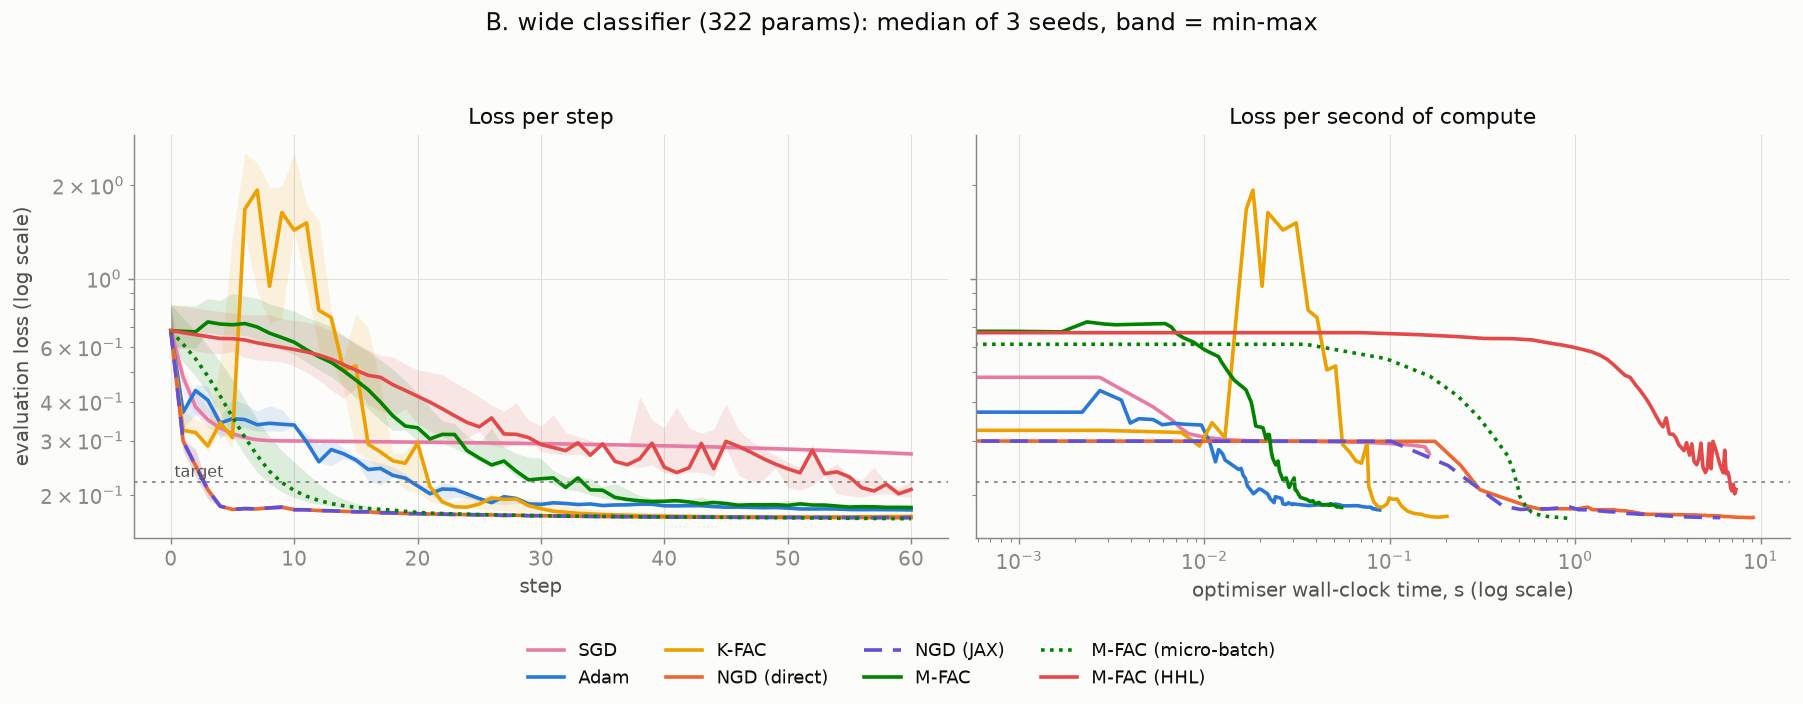

In [10]:
task = TASKS["B"]


def compute_task_B():
    print("tuning:")
    lrs = tune(task, ["SGD", "Adam", "K-FAC", "M-FAC", "M-FAC (window 8)", "M-FAC (micro-batch)"])
    lrs.update(tune(task, ["NGD (direct)"], steps=30))
    lrs["M-FAC (HHL)"] = lrs["M-FAC (window 8)"]
    results = benchmark(task, lrs)
    results["NGD (JAX)"] = [run_jax(task, lrs["NGD (direct)"], seed) for seed in SEEDS]
    lrs["NGD (JAX)"] = lrs["NGD (direct)"]
    return lrs, results


lrs_B, results_B = cached("task_B", compute_task_B, grids=LR_GRIDS, seeds=SEEDS, damping=DAMPING)
print()
summarise(task, results_B, lrs_B)
plot_task(task, results_B, ["SGD", "Adam", "K-FAC", "NGD (direct)", "NGD (JAX)", "M-FAC", "M-FAC (micro-batch)",
                             "M-FAC (HHL)"])

### C. Diffusion denoiser (50 parameters, stochastic minibatches)

Every step sees a fresh minibatch, so the curves show the *evaluation* loss on a fixed held-out batch. The
denoising loss can't reach zero, because the noise isn't fully predictable from $x_t$. The best run in the DDPM
notebook reached 0.287, so the target is 0.30.

[loaded results/benchmark_optimisers/task_C.json and task_C.npz]
tuning:
  SGD               1              (final loss by lr: 0.1: 0.473, 0.3: 0.449, 1: 0.406, 3: 0.432, 10: nan, 30: nan)
  Adam              0.3            (final loss by lr: 0.003: 0.462, 0.01: 0.416, 0.03: 0.38, 0.1: 0.347, 0.3: 0.338, 1: 0.633, 3: 1.02)
  NGD (direct)      0.5            (final loss by lr: 0.1: 0.311, 0.3: 0.294, 0.5: 0.293, 1: 0.299, 2: 0.835, 5: nan)
  K-FAC             0.5            (final loss by lr: 0.1: 0.382, 0.3: 0.352, 0.5: 0.344, 1: nan, 2: nan, 5: nan)
  M-FAC             0.001, λ=1e-05 (best: (0.001, λ=1e-05): 0.323, (0.003, λ=0.0001): 0.342, (0.001, λ=0.0001): 0.343, (0.03, λ=0.01): 0.358)  <- at the edge of the grid
  M-FAC (window 8)  0.03, λ=0.01   (best: (0.03, λ=0.01): 0.364, (0.01, λ=0.001): 0.377, (0.3, λ=0.1): 0.38, (0.003, λ=0.001): 0.404)
  M-FAC (micro-batch) 0.03, λ=0.001  (best: (0.03, λ=0.001): 0.307, (0.1, λ=0.01): 0.327, (0.3, λ=0.1): 0.359, (0.01, λ=0.001): 0.365)

C. 

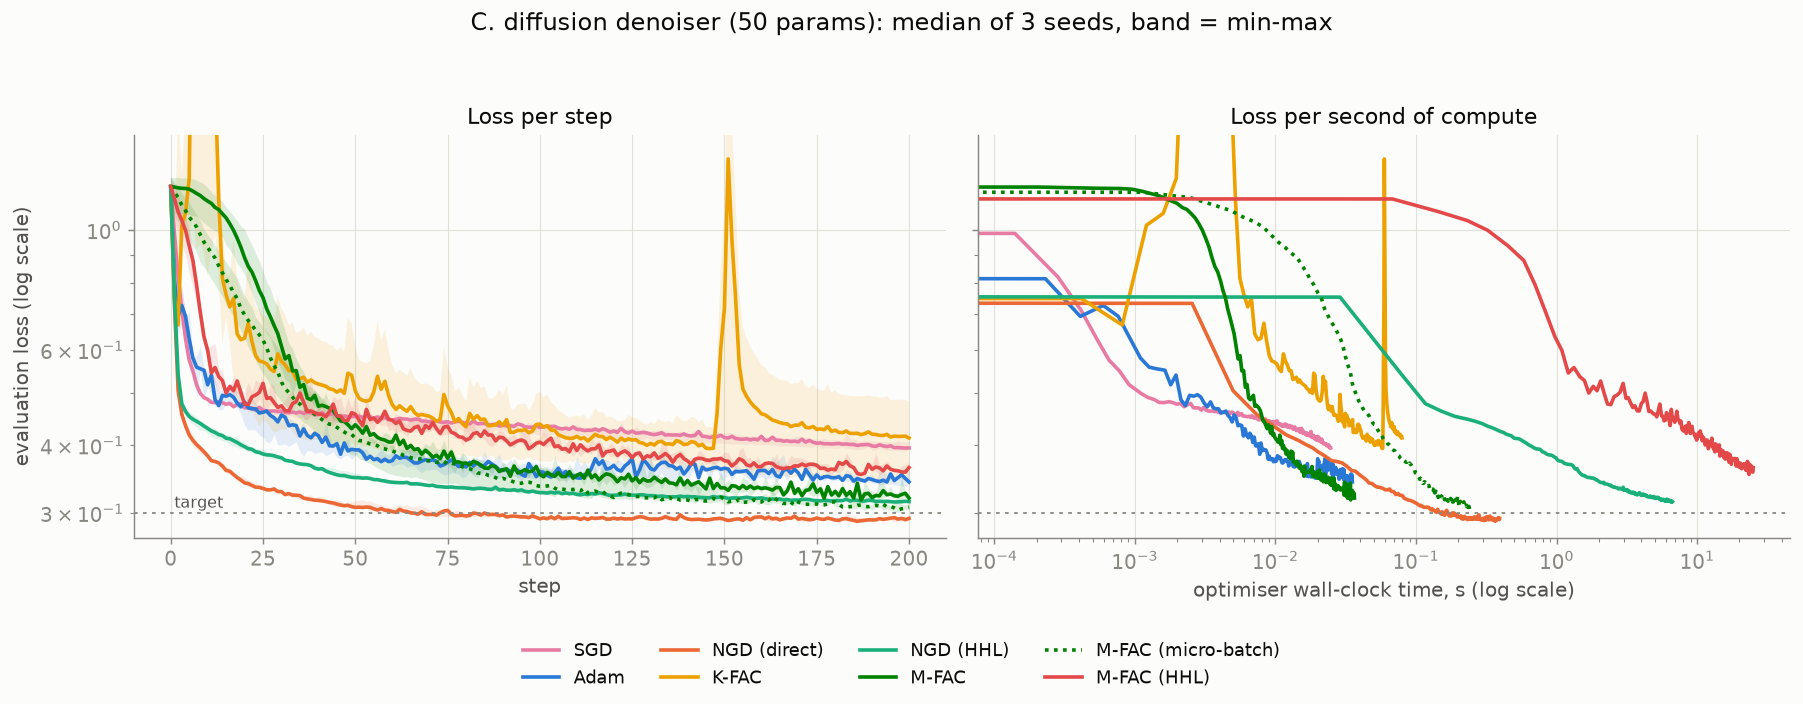

In [11]:
task = TASKS["C"]


def compute_task_C():
    print("tuning:")
    lrs = tune(task, LR_GRIDS)
    lrs["NGD (HHL)"] = lrs["NGD (direct)"]
    lrs["M-FAC (HHL)"] = lrs["M-FAC (window 8)"]
    return lrs, benchmark(task, lrs)


lrs_C, results_C = cached("task_C", compute_task_C, grids=LR_GRIDS, seeds=SEEDS, damping=DAMPING)
print()
summarise(task, results_C, lrs_C)
plot_task(task, results_C, ["SGD", "Adam", "NGD (direct)", "K-FAC", "NGD (HHL)", "M-FAC", "M-FAC (micro-batch)",
                             "M-FAC (HHL)"],
          ylim=(0.27, 1.5))  # clipped: K-FAC's early spikes reach ~1e4

## 4. Cost per step as the model grows

This section times one optimiser step for the classifier with hidden widths from 4 to 256, which is 22 to 1,282
parameters. Each point is the median of 5 timed steps, after one warm-up step (and, for JAX, compilation).
Dense NGD builds an $N\times n$ Jacobian and solves an $n\times n$ system. K-FAC only forms per-layer factors.
M-FAC needs one gradient and a $32\times32$ solve per step, timed once its window is full. M-FAC (micro-batch)
needs 32 micro-batch gradients and a $33\times33$ solve.

In [12]:
WIDTHS = (4, 8, 16, 32, 64, 128, 256)


def time_per_step(name, hidden, repeats=5):
    model = classifier(hidden)(0)
    values = TASKS["A"].values  # task A's 200 points
    hp = (0.01, 1e-1) if name.startswith("M-FAC") else 0.1
    if name.endswith("(JAX)"):  # fixed-size buffers: every step costs the same, so no window warm-up
        X, y = (jnp.asarray(a.numpy()) for a in TASKS["A"].data)
        opt = make_jax_optimizer(name, hp)
        update, params = jax.jit(opt.update), jax_classifier_params(model)
        state = opt.init(params)
        params, state, _ = jax.block_until_ready(update(params, state, X, y))
        times = []
        for _ in range(repeats):
            start = time.perf_counter()
            params, state, _ = jax.block_until_ready(update(params, state, X, y))
            times.append(time.perf_counter() - start)
        return np.median(times)
    opt = make_optimizer(name, model, hp, "fisher")
    warmup = 32 if name == "M-FAC" else 1  # fill M-FAC's window first, so steps cost their steady-state price
    times = []
    for i in range(repeats + warmup):
        start = time.perf_counter()
        if isinstance(opt, (NGD, KFAC)) or getattr(opt, "gradients", None) == "microbatch":
            opt.step(lambda: values(model, None))
        else:
            opt.zero_grad()
            values(model, None).mean().backward()
            opt.step()
        if i >= warmup:
            times.append(time.perf_counter() - start)
    return np.median(times)


SCALING = ("Adam", "K-FAC", "M-FAC", "M-FAC (JAX)", "M-FAC (micro-batch)", "NGD (direct)", "NGD (JAX)")
n_params = [5 * h + 2 for h in WIDTHS]
scaling = cached("scaling", lambda: {name: [time_per_step(name, h) * 1e3 for h in WIDTHS] for name in SCALING},
                 widths=WIDTHS, names=SCALING)

print(f"{'parameters':<12}" + "".join(f"{name:>21}" for name in SCALING) + "   (ms per step)")
for i, n in enumerate(n_params):
    print(f"{n:<12}" + "".join(f"{scaling[name][i]:>21.2f}" for name in SCALING))

[loaded results/benchmark_optimisers/scaling.json and scaling.npz]
parameters                   Adam                K-FAC                M-FAC          M-FAC (JAX)  M-FAC (micro-batch)         NGD (direct)            NGD (JAX)   (ms per step)
22                           2.52                 2.70                 1.13                 0.23                12.52                 3.56                 0.73
42                           2.92                 2.52                 1.17                 0.24                31.37                 9.16                 0.98
82                           3.56                 3.23                 0.83                 0.19                31.16                 6.40                 1.37
162                          2.22                 3.94                 1.32                 0.23                 3.91                 7.89                 2.41
322                          2.10                 5.48                 1.47                 0.36                 5.24

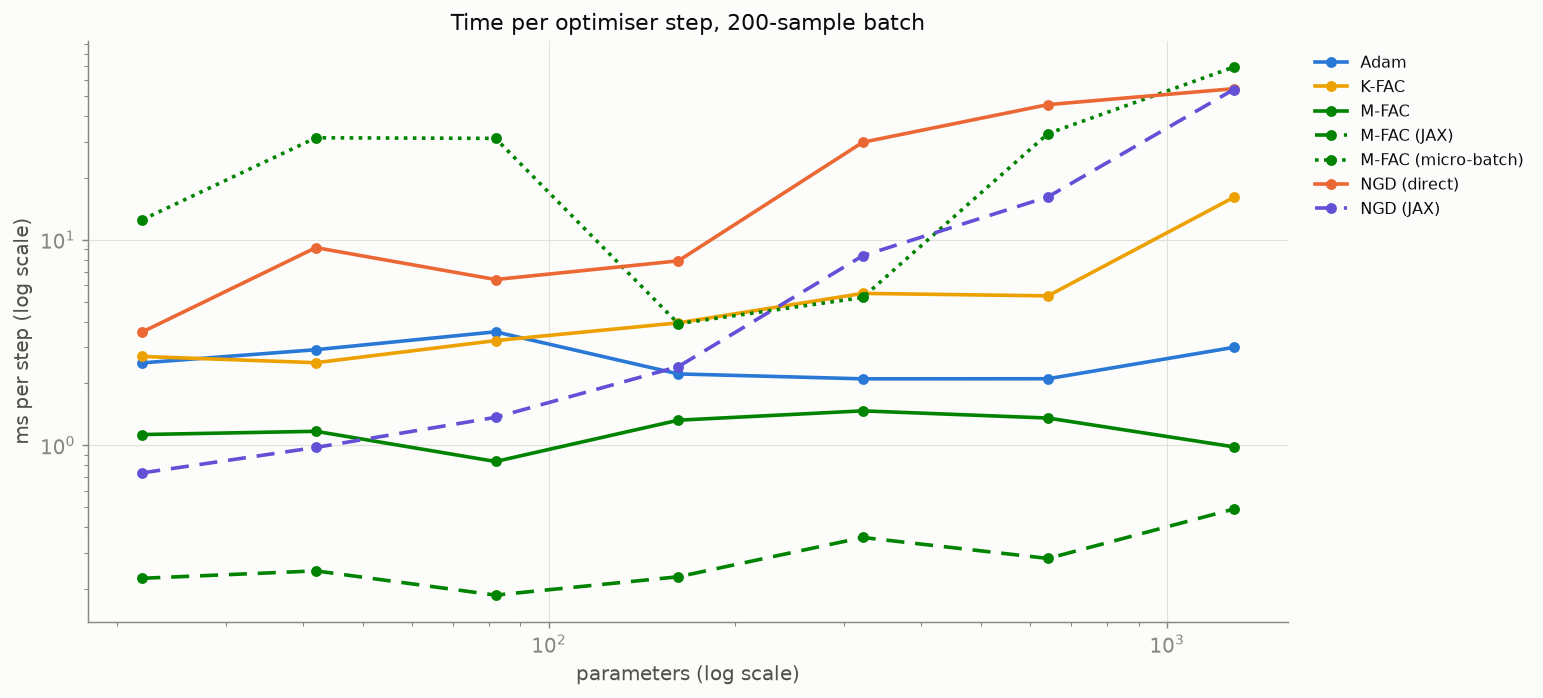

In [13]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for name in SCALING:
    ax.plot(n_params, scaling[name], color=color_of(name), marker="o", markersize=5, label=name,
            linestyle=linestyle_of(name))
ax.set(xscale="log", yscale="log", xlabel="parameters (log scale)", ylabel="ms per step (log scale)",
       title="Time per optimiser step, 200-sample batch")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout()
plt.show()

## 5. K-FAC (auto) under an HHL qubit budget

`KFAC(structure="auto")` reads the solver's `max_qubits` and uses the most exact structure that fits: the full
metric, then dense per-layer blocks, then Kronecker factors, then chunked factors. This sweep runs task A with
6 clock qubits and budgets from 8 to 12 qubits. `KFAC` averages curvature across steps (`stat_decay=0.95`), so
even the 12-qubit "full metric" run differs slightly from NGD (HHL), which uses only the current batch.

In [14]:
BUDGETS = (8, 9, 10, 11, 12)
task = TASKS["A"]
lr = lrs_A["NGD (direct)"]


def budget_kfac(q):
    def make(model):
        solver = QiskitHHLSolver(num_clock_qubits=6, max_qubits=q, match_damping_to_clock=True)
        return KFAC(model, lr=lr, damping=DAMPING, metric="fisher", solver=solver, structure="auto")
    return make


budget_runs = cached("kfac_budgets", lambda: {q: [run(task, None, lr, seed, optimizer=budget_kfac(q)) for seed in SEEDS]
                                              for q in BUDGETS},
                     budgets=BUDGETS, lr=lr, seeds=SEEDS, damping=DAMPING)
plans = {q: budget_kfac(q)(task.make_model(0)) for q in BUDGETS}  # cheap: just the factorisation plans
for q in BUDGETS:
    print(f"--- max_qubits = {q}: final loss {np.median([h['loss'][-1] for h in budget_runs[q]]):.4f}")
    print(plans[q].describe())

[loaded results/benchmark_optimisers/kfac_budgets.json and kfac_budgets.npz]


--- max_qubits = 8: final loss 0.0927
max system size: 2
0 (2->3)                    Kronecker A⊗G (chunked)   systems of size 2, 1  -> up to 8 qubits
2 (3->2)                    Kronecker A⊗G (chunked)   systems of size 2  -> up to 8 qubits
--- max_qubits = 9: final loss 0.0449
max system size: 4
0 (2->3)                    Kronecker A⊗G             systems of size 3  -> up to 9 qubits
2 (3->2)                    Kronecker A⊗G             systems of size 4, 2  -> up to 9 qubits
--- max_qubits = 10: final loss 0.0129
max system size: 8
0 (2->3)                    Kronecker A⊗G             systems of size 3  -> up to 9 qubits
2 (3->2)                    dense block               systems of size 8  -> up to 10 qubits
--- max_qubits = 11: final loss 0.0088
max system size: 16
0 (2->3)                    dense block               systems of size 9  -> up to 11 qubits
2 (3->2)                    dense block               systems of size 8  -> up to 10 qubits
--- max_qubits = 12: final loss 

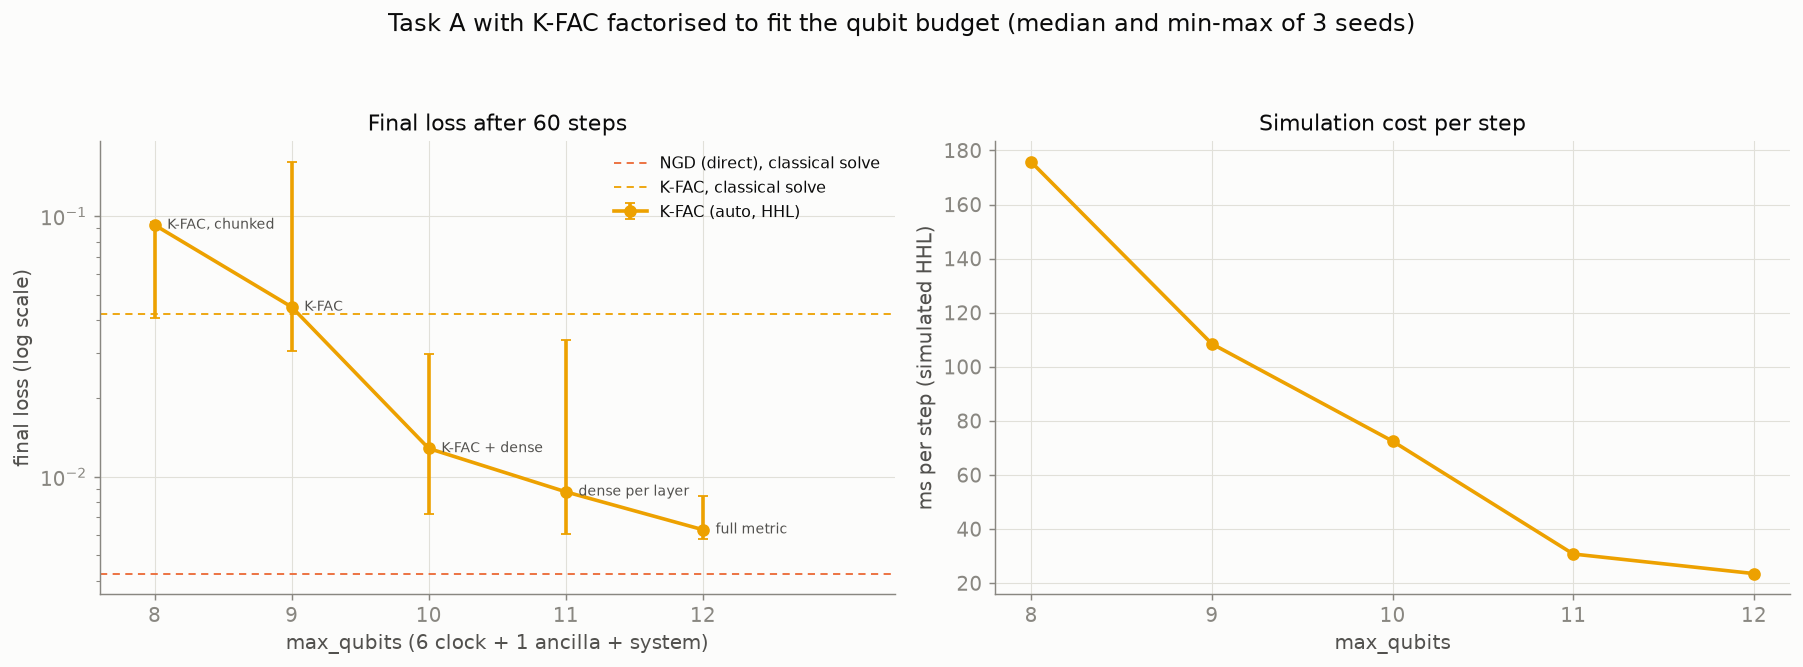

In [15]:
def structure_label(opt):
    if opt.plan[0].label == "all parameters":
        return "full metric"
    kinds = {b.kind for b in opt.plan}
    chunked = any(b.kind == "kronecker" and len(b.systems) > 2 for b in opt.plan)
    if kinds == {"dense"}:
        return "dense per layer"
    if kinds == {"kronecker"}:
        return "K-FAC, chunked" if chunked else "K-FAC"
    return "K-FAC + dense"


finals = np.array([[h["loss"][-1] for h in budget_runs[q]] for q in BUDGETS])
ms = np.array([np.median([np.mean(np.diff(h["time"])) * 1e3 for h in budget_runs[q]]) for q in BUDGETS])
reference = {name: np.median([h["loss"][-1] for h in results_A[name]]) for name in ("NGD (direct)", "K-FAC")}

fig, (ax_loss, ax_ms) = plt.subplots(1, 2, figsize=(14, 5.2))
median = np.median(finals, axis=1)
ax_loss.errorbar(BUDGETS, median, yerr=[median - finals.min(1), finals.max(1) - median], color=COLORS["K-FAC"],
                 marker="o", markersize=6, capsize=3, label="K-FAC (auto, HHL)")
for q, m in zip(BUDGETS, median):
    ax_loss.annotate(structure_label(plans[q]), (q, m), xytext=(7, 0), textcoords="offset points", ha="left",
                     va="center", fontsize=8, color=INK_2)
for name, value in reference.items():
    ax_loss.axhline(value, color=COLORS[name], linewidth=1, linestyle=(0, (4, 3)), label=f"{name}, classical solve")
ax_loss.set(yscale="log", xlabel="max_qubits (6 clock + 1 ancilla + system)", ylabel="final loss (log scale)",
            title="Final loss after 60 steps", xlim=(7.6, 13.4))
ax_loss.set_xticks(BUDGETS)
ax_loss.legend(loc="upper right", fontsize=9)
ax_ms.plot(BUDGETS, ms, color=COLORS["K-FAC"], marker="o", markersize=6)
ax_ms.set(xlabel="max_qubits", ylabel="ms per step (simulated HHL)", title="Simulation cost per step")
ax_ms.set_xticks(BUDGETS)
fig.suptitle("Task A with K-FAC factorised to fit the qubit budget (median and min-max of 3 seeds)", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 6. M-FAC under an HHL qubit budget

M-FAC's linear system is window × window, so the HHL system register needs only $\lceil\log_2 m\rceil$ qubits,
3 for a window of 8, whatever the model size. What the clock register needs depends on the conditioning of
$k\lambda I + GG^\top$. Consecutive gradients are nearly parallel, so that matrix is badly conditioned for small
$\lambda$ (condition numbers of 300–450 at $\lambda = 10^{-3}$ in the unit tests) and much better for larger
$\lambda$.

This section runs task A with a window of 8 and 6, 8 and 10 clock qubits (10–14 qubits in total), using
`match_damping_to_clock=True`. Every HHL solve is checked against `np.linalg.solve`.

**A control experiment.** M-FAC at its tuned learning rate turns out to be very sensitive to small perturbations:
whether a run escapes the loss plateau near 0.29 depends on tiny differences in the step. To separate that from
HHL's own error, the control runs *classical* M-FAC with a random relative error $\epsilon$ injected into every
solve, $z \leftarrow z + \epsilon\lVert z\rVert u$ with $u$ a random unit vector, at about the error levels HHL
produces. It uses 3 seeds × 5 noise draws per level.

In [16]:
CLOCKS = (6, 8, 10)
task = TASKS["A"]
hp = lrs_A["M-FAC (window 8)"]


def mfac_window8(solver):
    return lambda model: MFAC(model.parameters(), lr=hp[0], damping=hp[1], window=8, solver=solver)


NOISE_LEVELS = (0.0, 0.002, 0.006, 0.02)


def compute_clock_sweep():
    clock_runs, clock_errors, clock_success, clock_conds = {}, {}, {}, {}
    for nc in CLOCKS:
        errors, success, conds = [], [], []
        hhl = QiskitHHLSolver(num_clock_qubits=nc, max_qubits=nc + 4, match_damping_to_clock=True)

        def checked(A, b, hhl=hhl, errors=errors, success=success, conds=conds):
            x, exact = hhl(A, b), np.linalg.solve(A, b)
            errors.append(np.linalg.norm(x - exact) / np.linalg.norm(exact))
            success.append(hhl.last_info.success_probability)
            conds.append(np.linalg.cond(A))
            return x

        checked.max_dimension = hhl.max_dimension
        clock_runs[nc] = [run(task, None, None, seed, optimizer=mfac_window8(checked)) for seed in SEEDS]
        clock_errors[nc], clock_success[nc], clock_conds[nc] = map(np.array, (errors, success, conds))

    noise_runs = {}
    for eps in NOISE_LEVELS:
        noise_runs[eps] = []
        for draw in range(5 if eps else 1):
            rng = np.random.default_rng(draw)

            def noisy(A, b, eps=eps, rng=rng):
                z = np.linalg.solve(A, b)
                u = rng.normal(size=z.shape)
                return z + eps * np.linalg.norm(z) * u / np.linalg.norm(u)

            noise_runs[eps] += [run(task, None, None, seed, optimizer=mfac_window8(noisy)) for seed in SEEDS]
    return clock_runs, clock_errors, clock_success, clock_conds, noise_runs


clock_runs, clock_errors, clock_success, clock_conds, noise_runs = cached(
    "mfac_hhl_clocks", compute_clock_sweep, clocks=CLOCKS, noise_levels=NOISE_LEVELS, hp=hp, seeds=SEEDS)

print(f"condition number of k*damping*I + GG^T during these runs: median {np.median(clock_conds[6]):.0f}, "
      f"max {np.max(clock_conds[6]):.0f} (6 clock qubits resolve 31:1, 10 resolve 511:1)\n")
print(f"{'run':<36}{'per-solve error':>17}{'P(success)':>12}{'final loss: median (min-max)':>32}{'final <= target':>17}{'ms / step':>11}")


def report(label, runs, error="", success="", ms=None):
    finals = np.array([h["loss"][-1] for h in runs])
    hits = sum(f <= task.target for f in finals)
    timing = f"{ms:>11.0f}" if ms is not None else f"{'':>11}"
    print(f"{label:<36}{error:>17}{success:>12}{f'{np.median(finals):.4f} ({finals.min():.4f}-{finals.max():.4f})':>32}"
          f"{f'{hits}/{len(finals)}':>17}{timing}")


for eps in NOISE_LEVELS:
    report(f"classical + injected error {eps:.1%}" if eps else "classical (no injected error)", noise_runs[eps],
           f"{eps:.3f}" if eps else "0")
for nc in CLOCKS:
    ms = np.median([np.nanmean(np.diff(h["time"])) * 1e3 for h in clock_runs[nc]])
    report(f"HHL, {nc} clock qubits ({3 + nc + 1} qubits)", clock_runs[nc], f"{np.median(clock_errors[nc]):.3f}",
           f"{np.median(clock_success[nc]):.1e}", ms)

[loaded results/benchmark_optimisers/mfac_hhl_clocks.json and mfac_hhl_clocks.npz]
condition number of k*damping*I + GG^T during these runs: median 6, max 23 (6 clock qubits resolve 31:1, 10 resolve 511:1)

run                                   per-solve error  P(success)    final loss: median (min-max)  final <= target  ms / step
classical (no injected error)                       0                      0.0211 (0.0126-0.0677)              2/3           
classical + injected error 0.2%                 0.002                      0.0362 (0.0053-0.3799)             8/15           
classical + injected error 0.6%                 0.006                      0.1367 (0.0167-0.6754)             5/15           
classical + injected error 2.0%                 0.020                      0.0244 (0.0059-0.1966)            13/15           
HHL, 6 clock qubits (10 qubits)                 0.019     2.1e-02          0.0168 (0.0150-0.0217)              3/3         12
HHL, 8 clock qubits (12 qubits)      

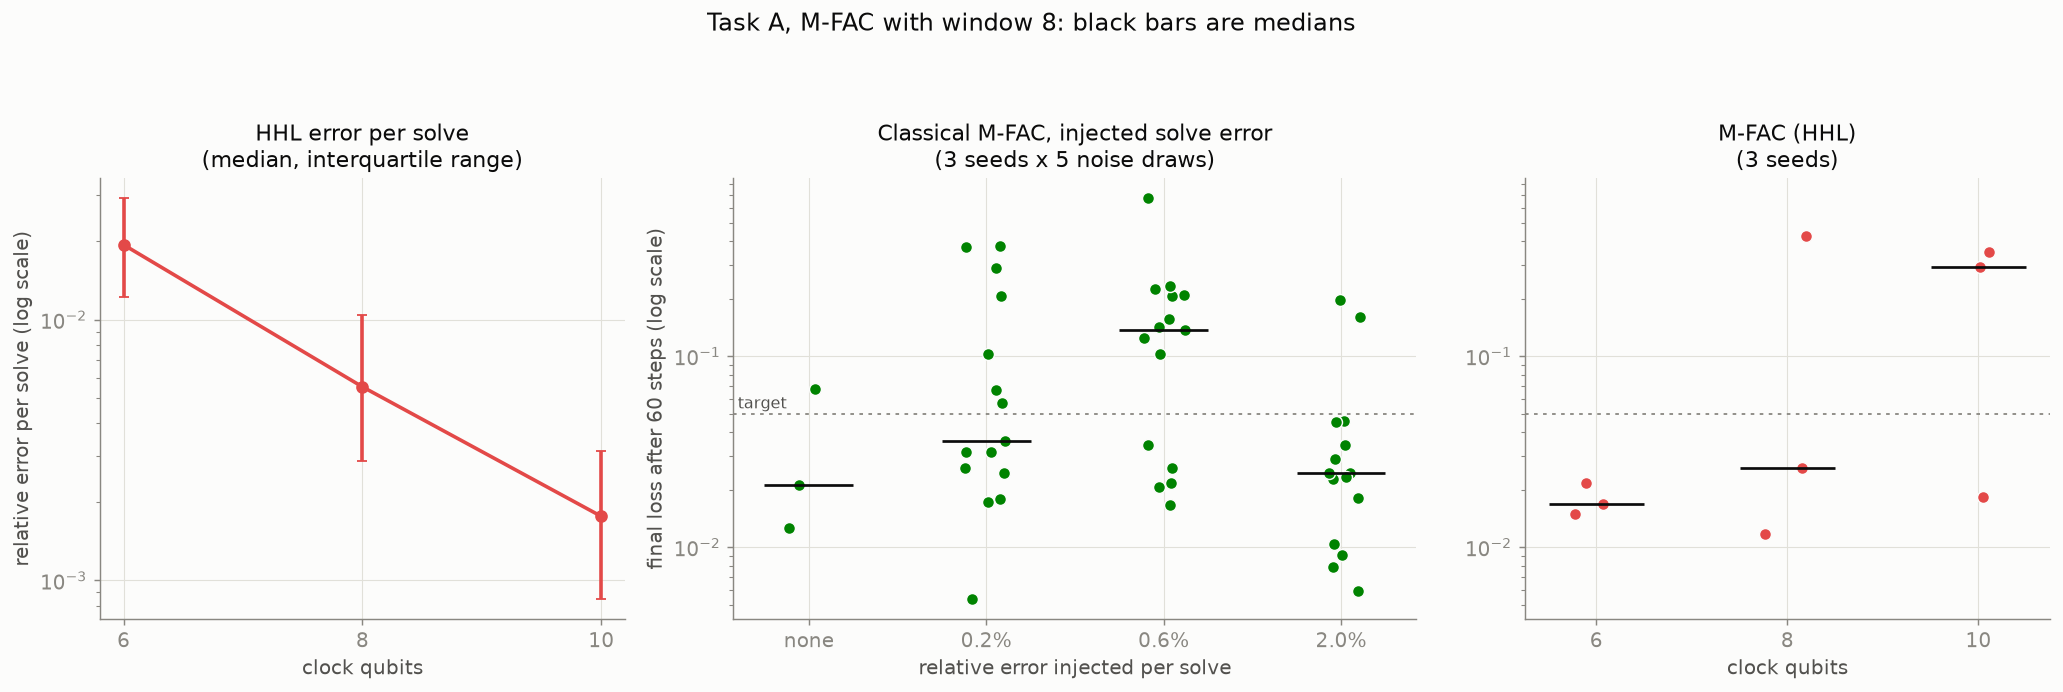

In [17]:
def strip(ax, groups, color, title, xlabel):
    rng = np.random.default_rng(0)
    for i, values in enumerate(groups.values()):
        x = i + rng.uniform(-0.12, 0.12, len(values))
        ax.scatter(x, values, s=44, color=color, edgecolor=SURFACE, linewidth=0.8, zorder=3)
        ax.hlines(np.median(values), i - 0.25, i + 0.25, color=INK, linewidth=1.5, zorder=4)
    ax.axhline(task.target, color=MUTED, linewidth=1, linestyle=(0, (2, 3)))
    ax.set_xticks(range(len(groups)), list(groups))
    ax.set(yscale="log", title=title, xlabel=xlabel)


err_q = np.array([np.percentile(clock_errors[nc], [25, 50, 75]) for nc in CLOCKS])
fig, (ax_err, ax_noise, ax_hhl) = plt.subplots(1, 3, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1.3, 1]})
ax_err.errorbar(CLOCKS, err_q[:, 1], yerr=[err_q[:, 1] - err_q[:, 0], err_q[:, 2] - err_q[:, 1]],
                color=COLORS["M-FAC (HHL)"], marker="o", markersize=6, capsize=3)
ax_err.set(yscale="log", xlabel="clock qubits", ylabel="relative error per solve (log scale)",
           title="HHL error per solve\n(median, interquartile range)")
ax_err.set_xticks(CLOCKS)
strip(ax_noise, {f"{e:.1%}" if e else "none": [h["loss"][-1] for h in noise_runs[e]] for e in NOISE_LEVELS},
      COLORS["M-FAC"], "Classical M-FAC, injected solve error\n(3 seeds x 5 noise draws)", "relative error injected per solve")
strip(ax_hhl, {str(nc): [h["loss"][-1] for h in clock_runs[nc]] for nc in CLOCKS},
      COLORS["M-FAC (HHL)"], "M-FAC (HHL)\n(3 seeds)", "clock qubits")
ax_noise.set_ylabel("final loss after 60 steps (log scale)")
ax_hhl.sharey(ax_noise)
ax_noise.annotate("target", (-0.4, task.target), xytext=(0, 3), textcoords="offset points", fontsize=9, color=INK_2)
fig.suptitle("Task A, M-FAC with window 8: black bars are medians", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

## 7. From M-FAC to NGD: which gradients go into the Fisher

M-FAC and NGD use the same formula, $\lambda I + \frac1m\sum_j g_jg_j^\top$, but with different gradients. The
paper's M-FAC uses the last $m$ *batch-mean* gradients, from past parameters. NGD uses the $N$ *per-sample*
gradients at the current parameters. On full-batch task A, the mean gradient carries only about 2–4% of the
per-sample gradient energy (a median of $\lVert\bar g\rVert^2 / \overline{\lVert g_i\rVert^2}$ of 0.02–0.04
along M-FAC's runs). So a window of mean gradients misses most of the spread that a Fisher is built from.

`MFAC(gradients="microbatch")` fills the window from the current step instead. The $N$ per-sample losses are split
into $m$ micro-batches with mean gradients $g_j$ and sizes $n_j$, and

$$F = \lambda I + \bar g\bar g^\top + \frac1m\sum_j n_j (g_j-\bar g)(g_j-\bar g)^\top .$$

The $n_j$ factor undoes the $1/n_j$ shrinkage of a micro-batch mean's spread. Without it, the curvature is
underestimated about $n_j$-fold and steps blow up on task B. The step is still a single
$(m+1)\times(m+1)$ solve with a basis-vector right-hand side, and with $m = N$ it is exactly NGD. This section
varies $m$ at NGD's tuned settings, so that the only thing changing is how much of the per-sample spread the
estimate captures. It also runs the $m = 7$ ($8\times8$) system through HHL.

In [18]:
def microbatch(m, lr, damping, solver="direct"):
    return lambda model: MFAC(model.parameters(), lr=lr, damping=damping, window=m, gradients="microbatch", solver=solver)


def finals(runs):
    return np.array([h["loss"][-1] for h in runs])


lr, damping = lrs_A["NGD (direct)"], DAMPING


def compute_slide():
    slide, hhl_errors = {}, {}
    for m in (2, 4, 8, 32, 200):
        slide[("A", m)] = [run(TASKS["A"], None, None, seed, optimizer=microbatch(m, lr, damping)) for seed in SEEDS]
    for nc in (6, 8):
        errors = []
        hhl = QiskitHHLSolver(num_clock_qubits=nc, max_qubits=nc + 4, match_damping_to_clock=True)

        def checked(A, b, hhl=hhl, errors=errors):
            x, exact = hhl(A, b), np.linalg.solve(A, b)
            errors.append(np.linalg.norm(x - exact) / np.linalg.norm(exact))
            return x

        checked.max_dimension = hhl.max_dimension
        slide[("A", f"HHL {nc}")] = [run(TASKS["A"], None, None, seed, optimizer=microbatch(7, lr, damping, checked))
                                     for seed in SEEDS]
        hhl_errors[nc] = np.median(errors)

    # Task B at lr 0.5: a low-rank estimate (m << 322) leaves the other directions with only the damping, and
    # NGD's tuned lr = 2 then diverges for m <= 8.
    for m in (8, 32, 128):
        slide[("B", m)] = [run(TASKS["B"], None, None, seed, optimizer=microbatch(m, 0.5, damping)) for seed in SEEDS]
    ngd_B_half = [run(TASKS["B"], "NGD (direct)", 0.5, seed) for seed in SEEDS]
    return slide, hhl_errors, ngd_B_half


slide, hhl_errors, ngd_B_half = cached("microbatch_slide", compute_slide, lr=lr, damping=damping, seeds=SEEDS)

print(f"{'task':<6}{'curvature estimate':<74}{'final loss: median (min-max)':>30}")
rows = [("A", "M-FAC, history window of 32 (tuned)", results_A["M-FAC"])]
rows += [("A", f"micro-batch, m = {m}" + (" (= NGD)" if m == 200 else ""), slide[("A", m)]) for m in (2, 4, 8, 32, 200)]
rows += [("A", f"micro-batch, m = 7, HHL {nc} clock qubits ({3 + nc + 1} qubits; per-solve error {hhl_errors[nc]:.1%})",
          slide[("A", f"HHL {nc}")]) for nc in (6, 8)]
rows += [("A", "NGD (direct)", results_A["NGD (direct)"]), ("B", "M-FAC, history window of 32 (tuned)", results_B["M-FAC"])]
rows += [("B", f"micro-batch, m = {m}, lr 0.5", slide[("B", m)]) for m in (8, 32, 128)]
rows += [("B", "NGD (direct), lr 0.5", ngd_B_half), ("B", "NGD (direct), tuned lr 2", results_B["NGD (direct)"])]
for task_key, label, runs in rows:
    f = finals(runs)
    print(f"{task_key:<6}{label:<74}{f'{np.median(f):.4f} ({f.min():.4f}-{f.max():.4f})':>30}")

[loaded results/benchmark_optimisers/microbatch_slide.json and microbatch_slide.npz]
task  curvature estimate                                                          final loss: median (min-max)
A     M-FAC, history window of 32 (tuned)                                               0.1747 (0.0117-0.2086)
A     micro-batch, m = 2                                                                0.1919 (0.0820-0.3149)
A     micro-batch, m = 4                                                                0.0135 (0.0063-0.2647)
A     micro-batch, m = 8                                                                0.0040 (0.0037-0.0052)
A     micro-batch, m = 32                                                               0.0040 (0.0039-0.0042)
A     micro-batch, m = 200 (= NGD)                                                      0.0043 (0.0042-0.0043)
A     micro-batch, m = 7, HHL 6 clock qubits (10 qubits; per-solve error 6.2%)          0.0045 (0.0043-0.0054)
A     micro-batch, m = 7, H

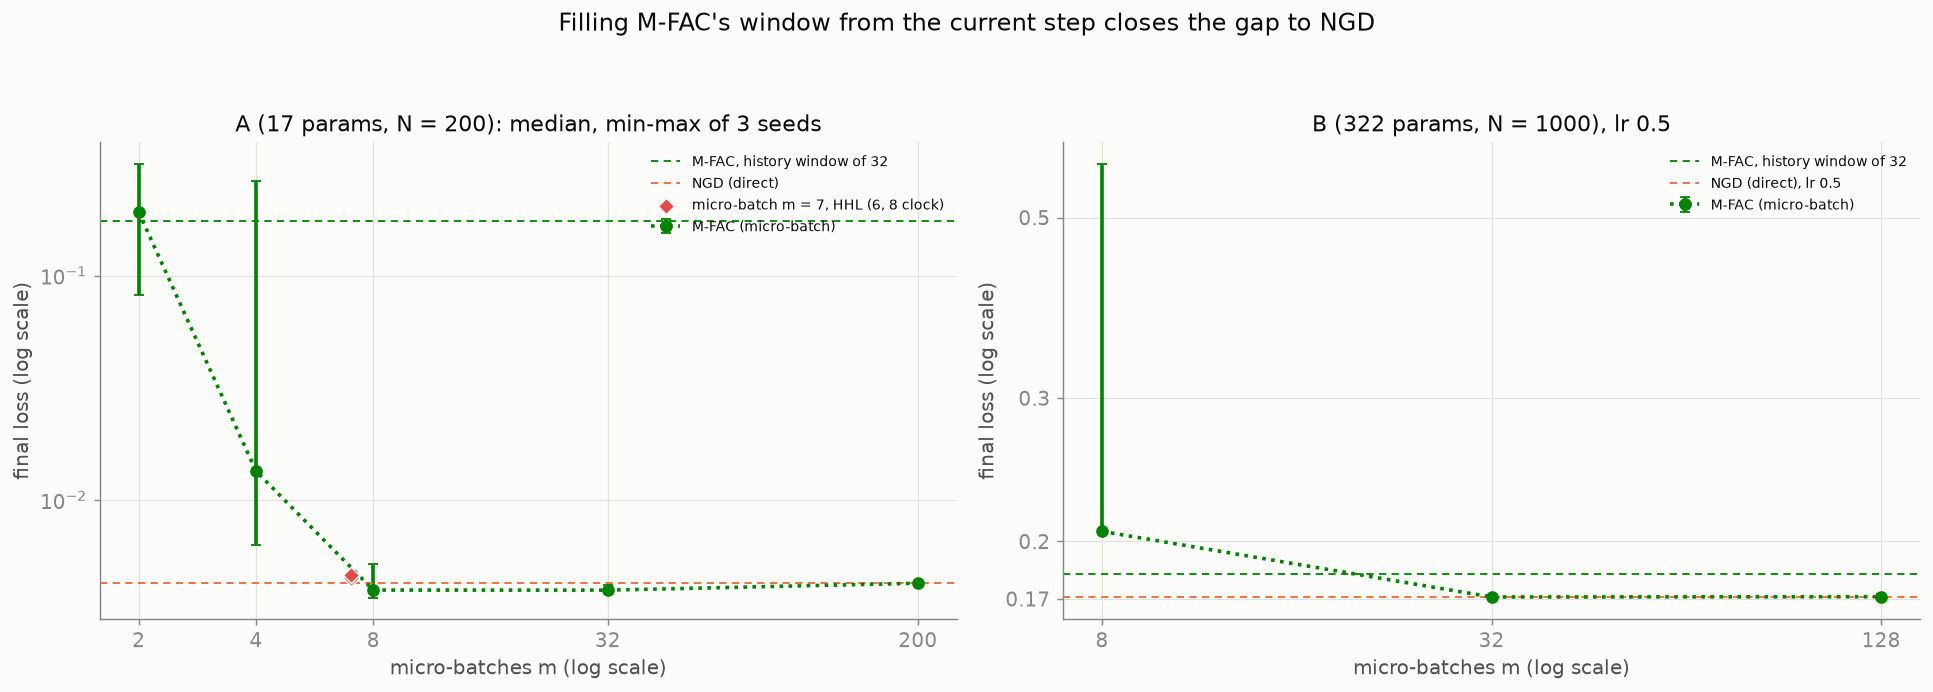

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
for ax, task_key, ms, ref_runs, ref_label in [
    (axes[0], "A", (2, 4, 8, 32, 200), results_A["NGD (direct)"], "NGD (direct)"),
    (axes[1], "B", (8, 32, 128), ngd_B_half, "NGD (direct), lr 0.5"),
]:
    f = np.array([finals(slide[(task_key, m)]) for m in ms])
    med = np.median(f, axis=1)
    ax.errorbar(ms, med, yerr=[med - f.min(1), f.max(1) - med], color=COLORS["M-FAC"], marker="o", markersize=6,
                capsize=3, linestyle=linestyle_of("M-FAC (micro-batch)"), label="M-FAC (micro-batch)")
    history = np.median(finals(results_A["M-FAC"] if task_key == "A" else results_B["M-FAC"]))
    ax.axhline(history, color=COLORS["M-FAC"], linewidth=1, linestyle=(0, (4, 3)), label="M-FAC, history window of 32")
    ax.axhline(np.median(finals(ref_runs)), color=COLORS["NGD (direct)"], linewidth=1, linestyle=(0, (4, 3)), label=ref_label)
    ax.set(xscale="log", yscale="log", xlabel="micro-batches m (log scale)", ylabel="final loss (log scale)")
    ax.set_xticks(ms, [str(m) for m in ms])
    ax.minorticks_off()
axes[0].scatter([7, 7], [np.median(finals(slide[("A", f"HHL {nc}")])) for nc in (6, 8)], color=COLORS["M-FAC (HHL)"],
                marker="D", s=40, zorder=4, edgecolor=SURFACE, linewidth=0.8, label="micro-batch m = 7, HHL (6, 8 clock)")
axes[0].set_title("A (17 params, N = 200): median, min-max of 3 seeds")
axes[1].set_title("B (322 params, N = 1000), lr 0.5")
axes[1].set_yticks([0.17, 0.2, 0.3, 0.5], ["0.17", "0.2", "0.3", "0.5"])  # the range sits inside one decade
axes[0].legend(loc="upper right", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Filling M-FAC's window from the current step closes the gap to NGD", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## Takeaways

These are three small tasks on one CPU, with 3 seeds each, so treat them as indicative rather than definitive.
One protocol detail matters for the rankings: NGD and K-FAC run at a fixed damping of $10^{-2}$, while the M-FAC
variants tune their damping jointly with the learning rate.

**Per step, natural gradient with current-step curvature wins clearly. Per second, it depends on the
implementation.**
* *A (17 params):* NGD reached the target in 11 steps on every seed, and M-FAC (micro-batch) in 13, finishing at
  0.0043 and 0.0020. Tuned Adam reached it on 2 of 3 seeds (median 45 steps), K-FAC on 2 of 3 (53), and SGD on 1
  of 3.
* *B (322 params):* NGD reached the target in 3 steps and M-FAC (micro-batch) in 9, against about 20 for Adam and
  K-FAC. M-FAC (micro-batch) finished lowest (0.168), then NGD (0.169), K-FAC (0.171), Adam (0.179) and M-FAC
  (0.182). A dense torch NGD step costs 100–300 ms here, so tuned Adam reaches the target first in wall-clock
  time.
* *C (stochastic denoiser):* only NGD reached the target (66 steps). M-FAC (micro-batch) came next (0.307), then
  NGD (HHL) (0.315) and M-FAC (0.320). Adam (0.343), K-FAC and SGD plateaued higher.

**JAX is much faster for the same algorithms.** JAX NGD matches torch NGD to about $10^{-14}$. It ran 5–20×
faster per step on task A and 1.2–4× faster on task B (timings vary between runs). The torch version builds the
per-sample Jacobian through closure-based autograd, which costs 10–20 ms per step even at 20 parameters. JAX
M-FAC was the cheapest optimiser in the scaling chart, at 0.2–1.4 ms per step, below torch Adam at every size.

**K-FAC is the scalable approximation, but less robust here.** Its cost per step stays within about 12× of
Adam's up to 1,282 parameters. Dense torch NGD is 15–100× slower than Adam there, depending on the run; its
timings are noisy, from torch's thread scheduling on small operations. On these tiny networks the Kronecker
approximation is coarse. It lagged dense NGD on A, spiked early on B at its tuned learning rate, and was
unstable on the stochastic denoiser (C).

**The paper's M-FAC is cheap but fragile at this scale.** Its window of past batch-mean gradients costs one
gradient plus a $32\times32$ solve per step, close to Adam. It was competitive on B (0.182) and C (0.320). On C its
tuned setting (lr $10^{-3}$, λ $10^{-5}$, the paper's own regime) sits at the corner of the grid. On A it is very
sensitive: the setting tuned on seed 0 (0.0117) failed to leave the loss plateau on the other two seeds (median
0.175). The same sensitivity is why JAX and torch M-FAC agree only to about $10^{-7}$.

**Filling M-FAC's window from the current step closes the gap to NGD (section 7).** On full-batch task A, the mean
gradient carries only about 2–4% of the per-sample gradient energy, so a window of past mean gradients misses
most of the curvature signal. With micro-batch gradients of the current step and NGD's settings, task A's final
loss falls from 0.19 at $m = 2$ to 0.0040 at $m = 8$, already equal to NGD's 0.0043, and $m = 200$ *is* NGD. On B
at lr 0.5, $m = 32$ reached 0.1709 against 0.1708 for NGD at the same learning rate. Tuned with its own damping,
it was the best optimiser on A and B. That edge over NGD comes from the damping, though, not from a better
estimate: NGD with damping $10^{-3}$ to $3\times10^{-3}$ reaches 0.0021–0.0022 on A, which we checked separately.
It costs 32 micro-batch gradients per step: 5–70 ms in the scaling chart. That is between M-FAC and dense NGD,
and close to dense NGD at 1,282 parameters (68 against 90 ms in the final run).

**For HHL, micro-batch M-FAC is the sweet spot.** Its $8\times8$ system ($m = 7$) has a basis-vector right-hand
side and needs 10 qubits with 6 clock qubits. On A it trained to 0.0045 against 0.0043 for classical NGD, with
6.2% error per solve. Dense NGD (HHL) needs 12 qubits for this model, and its system grows with the model. The
micro-batch Gram matrix does get worse conditioned on bigger tasks: condition numbers of 600–800 on B in a
separate check, which would need about 10 clock qubits.

**NGD (HHL) keeps NGD's step efficiency when the spectrum fits the clock.** With `match_damping_to_clock`, it
matched classical NGD on A (0.0042 against 0.0043) and came close on C (0.315 against 0.293). Plain HHL drops
small eigenvalues, so it trained more slowly and failed on one seed of A.

**The paper's M-FAC with HHL: on A, M-FAC's sensitivity decides the outcome, not HHL's accuracy.** Its HHL system
is $8\times8$ whatever the model size, which made it the only HHL variant on the 322-parameter task B (0.208
against 0.189 for its classical twin). On C it matched its twin (0.364 against 0.364). In section 6, HHL's error
per solve falls from 1.9% with 6 clock qubits to 0.2% with 10, yet the final losses scatter (medians 0.017,
0.026 and 0.29). Classical M-FAC with 0.2–2% injected solve error scatters just as widely (0.005–0.68). More clock
qubits also cut the postselection probability from $2\times10^{-2}$ to $1.4\times10^{-4}$.

**Under a qubit budget, every extra qubit helps K-FAC (auto).** On task A its final loss falls steadily from
about 0.09 at 8 qubits (chunked Kronecker factors) to about 0.006 at 12 (the full metric). From 10 qubits
upwards, even the partially factorised plans beat classical K-FAC, because the dense layer blocks keep
within-layer correlations that the Kronecker product drops.